In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

img = np.full((400, 600, 3), 255, dtype=np.uint8)       # white canvas
DARK = (50, 50, 50)

# triangle
cv2.fillPoly(img, [np.array([[100, 150], [40, 50], [160, 50]])], DARK)
# square
cv2.rectangle(img, (230, 50), (330, 150), DARK, -1)
# rectangle (wider than tall)
cv2.rectangle(img, (400, 60), (560, 140), DARK, -1)
# pentagon (5 points around a centre)
pent = [[int(100 + 60*np.cos(np.radians(-90 + 72*k))),
         int(300 + 60*np.sin(np.radians(-90 + 72*k)))] for k in range(5)]
cv2.fillPoly(img, [np.array(pent)], DARK)
# two circles
cv2.circle(img, (300, 300), 50, DARK, -1)
cv2.circle(img, (470, 300), 40, DARK, -1)

cv2.imwrite('shapes.png', img)



True

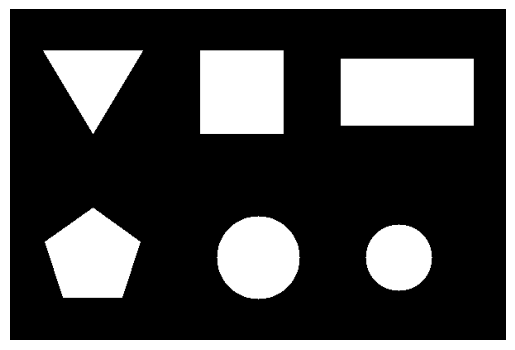

In [5]:
img=cv2.imread('shapes.png')
gray=cv2.cvtColor(img,cv2.COLOR_BGR2GRAY)

_,thresh=cv2.threshold(gray,127,255,cv2.THRESH_BINARY_INV)

plt.imshow(thresh,cmap='gray')   
plt.axis('off')
plt.show()



In [7]:
contours,_=cv2.findContours(thresh,cv2.RETR_EXTERNAL,cv2.CHAIN_APPROX_SIMPLE)
print('contours found:',len(contours))

contours found: 6


In [8]:
output=img.copy()

counts={
    'Triangle':0,
    'Square':0,
    'Rectangle':0,
    'Pentagon':0,
    'Circle':0
}

In [12]:
for c in contours:
    if cv2.contourArea(c) <500:
        continue
    prei=cv2.arcLength(c, True)
    approx=cv2.approxPolyDP(c,0.02*prei,True)
    corner=len(approx)

    if corner==3:
        name='Triangle'
    elif corner==4:
        x,y,w,h=cv2.boundingRect(approx)
        ratio=w/h
        name = "Square" if 0.95 <= ratio <= 1.05 else "Rectangle"
    elif corner==5:
        name='Pentagon'
    else:
        name='Circle'
    counts[name]+=1

    #find the center of the shape
    M=cv2.moments(c)
    cx=int(M['m10']/M['m00'])
    cy=int(M['m01']/M['m00'])
    
    # draw outline and name
    cv2.drawContours(output, [c], -1, (0, 255, 0), 3)
    cv2.putText(output, name, (cx - 40, cy), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 0, 255), 2)

Triangles: 1
Squares: 1
Rectangles: 1
Pentagons: 1
Circles: 3


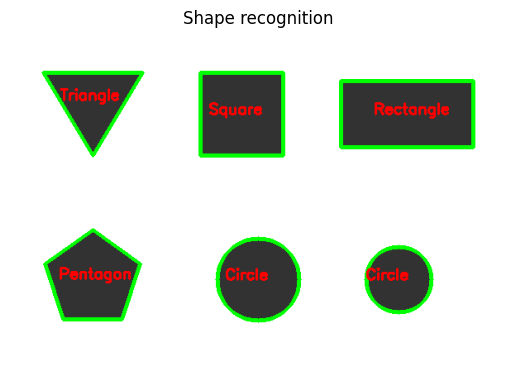

In [13]:
print("Triangles:", counts["Triangle"])
print("Squares:", counts["Square"])
print("Rectangles:", counts["Rectangle"])
print("Pentagons:", counts["Pentagon"])
print("Circles:", counts["Circle"])

plt.imshow(cv2.cvtColor(output, cv2.COLOR_BGR2RGB))
plt.title("Shape recognition")
plt.axis('off')
plt.savefig('p25_shapes.png', dpi=150)
plt.show()